# Tổng hợp các thí nghiệm HeteroES

Bảng gom kết quả các notebook thí nghiệm (`results/*.json`). "Đúng" = điểm 1 trên tập test, chấm **một lần** ở cuối;
p là kiểm định McNemar chính xác (mô hình gốc so với checkpoint được chọn). Cột "đúng / đã xong" là tỉ lệ đúng trên các
câu mô hình trả lời xong trong giới hạn token: nếu cột này không tăng thì mức tăng chỉ là do viết gọn hơn.

In [1]:
import json
from pathlib import Path

HERE = Path.cwd()


def table(folder):
    print(f"{'thí nghiệm':22} {'mô hình':30} {'n':>5} {'gốc':>5} {'sau ES':>7} {'p':>9}  {'đúng/đã xong: gốc → sau':>24}")
    for path in sorted((folder / "results").glob("*.json")):
        s = json.loads(path.read_text())
        t = s["test"]
        f = s.get("finished") or {}
        cells = [v for k, v in f.items()]
        ratio = (lambda x: x["rightAmongFinished"] / max(x["finished"], 1))
        change = f"{ratio(cells[0]):6.1%} → {ratio(cells[-1]):6.1%}" if cells else "—"
        print(f"{s['name']:22} {s['model'][:30]:30} {t['base']['count']:5} {t['base']['correct']:5} "
              f"{t['selected']['correct']:7} {s['comparison']['mcnemarExactP']:9.2g}  {change:>24}")


table(HERE)

thí nghiệm             mô hình                            n   gốc  sau ES         p   đúng/đã xong: gốc → sau
e4-countdown-qwen15    Qwen/Qwen2.5-1.5B-Instruct       250     4      31   4.6e-07             2.1% →  12.4%


## Tốc độ: một thế hệ dùng thời gian vào đâu

Trung vị giây mỗi thế hệ theo từng bước, không tính các thế hệ có chấm validation và thế hệ bị tạm dừng. Mốc 1 GPU là run
ngắn 6 thế hệ chỉ trên 5070 Ti của Nhân, cùng cấu hình. Đọc từ nhật ký sự kiện và ledger của coordinator (chỉ có trên máy coordinator). Chỉ bước **chấm candidate** chia được
cho nhiều GPU; cập nhật ES, phát hành trọng số và ghi điểm khôi phục chạy tuần tự trên coordinator, nên thêm GPU không
làm chúng ngắn đi (định luật Amdahl). Các run của E4 ghi điểm khôi phục **mỗi thế hệ**; từ 25/11 mặc định là 10 thế hệ
một lần. Dòng `e4-speed-backup10 one-gpu` (26/11) là cùng cấu hình E4 trên một 5070 Ti với điểm khôi phục 10 thế hệ một
lần: bước "điểm khôi phục + mở thế hệ sau" giảm rõ, còn tổng một thế hệ chủ yếu phụ thuộc bước chấm candidate.

e4-countdown-qwen15 segment-01   2 GPU  tổng   81.4 s = chấm candidate 58.4 + cập nhật ES 9.0 + phát hành trọng số 1.9 + điểm khôi phục + mở thế hệ sau 8.5
      5070ti-nhan  vào việc sau  19.9 s   2.84 s/candidate   16.7 candidate/thế hệ
      5070ti-nhut  vào việc sau  19.6 s   2.95 s/candidate   15.6 candidate/thế hệ
e4-countdown-qwen15 segment-02   4 GPU  tổng   73.5 s = chấm candidate 46.2 + cập nhật ES 11.9 + phát hành trọng số 1.9 + điểm khôi phục + mở thế hệ sau 12.9
      3060-quang   vào việc sau  40.1 s   6.43 s/candidate    2.6 candidate/thế hệ
      3060-thao    vào việc sau  39.5 s   6.20 s/candidate    2.8 candidate/thế hệ
      5070ti-nhan  vào việc sau  24.5 s   2.56 s/candidate   13.4 candidate/thế hệ
      5070ti-nhut  vào việc sau  24.4 s   2.64 s/candidate   13.3 candidate/thế hệ
e4-countdown-qwen15 one-gpu      1 GPU  tổng  112.0 s = chấm candidate 84.8 + cập nhật ES 11.5 + phát hành trọng số 1.1 + điểm khôi phục + mở thế hệ sau 7.8
      5070ti-nhan  vào việc sau

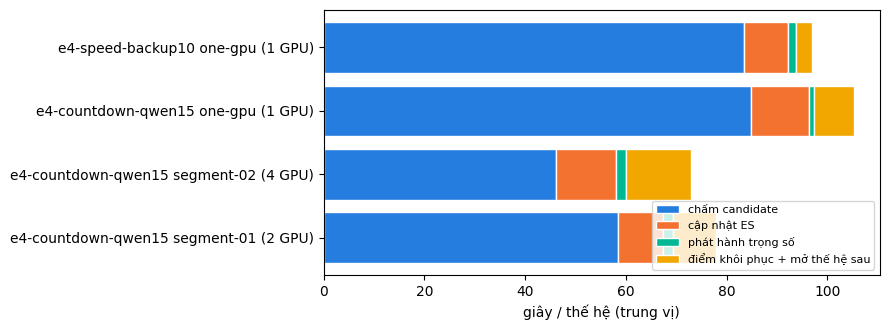

In [2]:
import sys

sys.path[:0] = [str(HERE), str(HERE.parents[1] / "src")]
import matplotlib.pyplot as plt
import runner

names = {d.worker_id: d.name for d in __import__("heteroes.sdk_lab", fromlist=["Lab"]).Lab.from_session().devices()}
rows = []
for path in sorted((HERE / "state").glob("*.json")):
    state = json.loads(path.read_text())
    runs = [(k, v) for k, v in state.get("segments", {}).items()] + ([("one-gpu", state["one-gpu"])] if "one-gpu" in state else [])
    for key, entry in runs:
        p = runner.phases(entry["experimentId"])
        if p and p["generations"]:
            rows.append((f"{path.stem} {key}", entry["workers"], p, runner.device_timing(entry["experimentId"], names)))
steps = ["chấm candidate", "cập nhật ES", "phát hành trọng số", "điểm khôi phục + mở thế hệ sau"]
for label, workers, p, devices in rows:
    print(f"{label:32} {len(devices)} GPU  tổng {p['tổng']:6.1f} s = " + " + ".join(f"{s} {p[s]}" for s in steps))
    for device, d in sorted(devices.items()):
        print(f"      {device:12} vào việc sau {d['startSeconds']:5.1f} s  {d['secondsPerCandidate']:5.2f} s/candidate  "
              f"{d['candidatesPerGeneration']:5.1f} candidate/thế hệ")
fig, ax = plt.subplots(figsize=(9, 0.6 * len(rows) + 1))
left = [0] * len(rows)
for step, color in zip(steps, ["#257de0", "#f47230", "#00b894", "#f2a600"]):
    values = [p[step] for _, _, p, _ in rows]
    ax.barh(range(len(rows)), values, left=left, color=color, label=step, edgecolor="white")
    left = [a + b for a, b in zip(left, values)]
ax.set_yticks(range(len(rows)), [f"{label} ({len(d)} GPU)" for label, _, _, d in rows])
ax.set_xlabel("giây / thế hệ (trung vị)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## Lần 1 (đêm 24 → 25/11) và các run trước đó

Lần 1 nằm trong `v1/` (notebook, kết quả, quyết định). Phát hiện chính, và là lý do làm lại:

| Kết quả lần 1 | Có ý nghĩa? | Vì sao |
|---|---|---|
| E1 GSM8K × Qwen 0.5B, 462 → 528/1319 | không | 320 token: tỉ lệ đúng trên câu đã xong **giảm** 51% → 47%; mức tăng chỉ do trả lời xong nhiều câu hơn |
| E3 GSM8K × Qwen 1.5B, 703 → 871/1319 | không | 320 token: đúng/đã xong 77,5% → 76,8%; 170 trong 251 câu được sửa là câu mà mô hình gốc bị cắt |
| E2 phép nhân × SmolLM2-360M, 0 → 0 | không | mô hình không học được gì |
| E4 Countdown × Qwen 1.5B, 4 → 31/250 | **có** | đúng/đã xong 2,1% → 12,4%; mô hình gốc chỉ 1,6% kể cả với 1024 token |
| Countdown × Qwen 0.5B (24/11, ngoài lab), 0 → 33/250 | **có** | mô hình gốc 0/250 kể cả với 1024 token |
| Phép nhân × Qwen 0.5B (trước 24/11, ngoài lab), 95 → 186/300 | một phần | phần lớn là học ghi `\boxed{}` (179 → 300 câu có ô), nhưng đúng trên câu có ô vẫn tăng 53% → 62% |

E2 của lần 2 đổi sang Llama-3.2-1B. SmolLM2-1.7B (họ Llama) không chạy được trên RTX 3060 12 GB với bộ suy luận nghiêm ngặt: mô hình
này không dùng GQA (32 đầu KV, bằng số đầu attention), nên bộ nhớ KV của lô 8 câu đã cần khoảng 6,1 GB, vượt ngân sách
4,8 GB (40% VRAM) của decoder. Llama 3.2 dùng kiểu RoPE `llama3`: từ 25/11 decoder tính được kiểu RoPE này (kiểm
trên CPU so với `transformers`), và ngày 26/11 Llama-3.2-1B đã chạy trên RTX 5070 Ti với golden parity riêng
(`acceptance/golden/strict-b22-llama32.json`); còn chờ một RTX 3060 chạy lại probe đó, rồi E2 chạy với Llama-3.2-1B.
SmolLM2-360M thì chạy được nhưng chỉ đúng 2/128 câu GSM8K. Đây là giới hạn hiện tại của hệ thống: mô hình cần GQA
và RoPE mặc định để vừa một GPU 12 GB.

Lần 1 cũng gần như không phân tán: E1 và E2 chạy hoàn toàn trên một 5070 Ti, E3 chỉ có máy Quang góp 14 trong 3200
candidate; chỉ E4 chạy trên 2 GPU (190/190 audit khớp).

In [3]:
table(HERE / "v1")

thí nghiệm             mô hình                            n   gốc  sau ES         p   đúng/đã xong: gốc → sau
e1-gsm8k-qwen05        Qwen/Qwen2.5-0.5B-Instruct      1319   462     528   7.1e-05                         —
e2-arith-smollm2       HuggingFaceTB/SmolLM2-360M-Ins   300     0       0         1                         —
e3-gsm8k-qwen15        Qwen/Qwen2.5-1.5B-Instruct      1319   703     871   9.2e-21                         —
e4-countdown-qwen15    Qwen/Qwen2.5-1.5B-Instruct       250     4      31   1.1e-07                         —
